# 02 · EDA — Embudo de conversión y comportamiento de los clientes

**Proyecto:** Análisis de clientes de un servicio de suscripción (Foodie-Fi) · **Etapa 2 de 5**
**Entrada:** `data/processed/foodie_fi_customers_clean.csv` y `foodie_fi_events_clean.csv` (generados en el notebook 01)

## Preguntas de negocio que responde este notebook
1. ¿Qué proporción de los trials se convierte en clientes de pago, y a qué plan?
2. ¿Esa conversión cambia según el mes en que el cliente empezó?
3. ¿Qué recorridos de planes siguen los clientes?
4. ¿Cuándo hacen upgrade o cancelan, y desde qué plan?
5. ¿Cancela más quien arranca en el plan básico que en el pro?
6. ¿Cuánto pesa cada plan en la base activa?

## Reglas de lectura (heredadas del notebook 01)
- **Censura:** la observación termina el 30-abr-2021. Un cliente "sin cambios" puede cambiar mañana. Para comparar planes uso **ventanas completas**
  (sólo clientes con suficiente tiempo de observación) o **tasas por exposición**, nunca porcentajes crudos sobre ventanas distintas.
- **Advertencia A2:** en planes mensuales ningún evento ocurre pasados **184 días**; no se interpreta la "lealtad" más allá de ese plazo.
- **Advertencia A1:** 19 planes anuales vencidos sin evento se consideran activos; se hace análisis de sensibilidad donde importa.
- **Rigor:** una diferencia **sólo se presenta como hallazgo si supera un test estadístico** (umbral convencional α = 0,05). Las diferencias que no lo superan se reportan como *no concluyentes*.
- **Ingresos:** son **estimaciones con precio de lista** (moneda no especificada), no pagos reales.

## Índice
1. Configuración y carga
2. Indicadores globales
3. Embudo: del trial al plan de pago
4. Conversión por cohorte
5. Mezcla de planes
6. Recorridos de clientes
7. Tiempos hasta upgrade o cancelación
8. Churn: ¿básico vs. pro mensual?
9. Upgrades: cuándo ocurren
10. Valor estimado de la base activa
11. Hallazgos (Finding / Evidence / Impact / Recommendation)
12. Limitaciones y próximos pasos

## 1. Configuración y carga

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Colores consistentes por plan en todos los gráficos
PLAN_COLORS = {"trial": "#9AA5B1", "basic monthly": "#4C72B0", "pro monthly": "#DD8452",
               "pro annual": "#55A868", "churn": "#C44E52"}
MONTHLY = ["basic monthly", "pro monthly"]
ALPHA = 0.05

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

def pct(x, d=1):
    return f"{x * 100:.{d}f}%"

customers = pd.read_csv(PROC_DIR / "foodie_fi_customers_clean.csv",
                        parse_dates=["trial_start_date", "first_paid_date", "churn_date", "last_event_date", "observation_end"])
events = (pd.read_csv(PROC_DIR / "foodie_fi_events_clean.csv", parse_dates=["start_date", "next_start_date"])
            .sort_values(["customer_id", "start_date"]).reset_index(drop=True))
OBSERVATION_END = customers["observation_end"].iloc[0]

# Conciliación con el notebook 01: si algo no cuadra, el análisis se detiene
assert len(customers) == 1000 and len(events) == 2650
assert (customers["converted_to_paid"].sum(), customers["is_churned"].sum()) == (908, 307)
print(f"✔ Datos cargados y conciliados con el notebook 01 | corte de observación: {OBSERVATION_END.date()}")

✔ Datos cargados y conciliados con el notebook 01 | corte de observación: 2021-04-30


In [2]:
# Variables auxiliares sobre la tabla de eventos
events["gap_days"] = events.groupby("customer_id")["start_date"].diff().dt.days        # días desde el evento anterior
events["next_plan_name"] = events.groupby("customer_id")["plan_name"].shift(-1)
events["prev_start_date"] = events.groupby("customer_id")["start_date"].shift(1)

# Tope de los planes mensuales (advertencia A2): se recalcula, no se hardcodea
MONTHLY_CAP = int(events.loc[events["prev_plan_name"].isin(MONTHLY), "gap_days"].max())
assert MONTHLY_CAP == 184, MONTHLY_CAP   # coincide con el notebook 01
print("Tope observado en planes mensuales:", MONTHLY_CAP, "días")

Tope observado en planes mensuales: 184 días


## 2. Indicadores globales

In [3]:
n = len(customers)
conv = int(customers["converted_to_paid"].sum())
churn_total = int(customers["is_churned"].sum())
churn_trial = int((customers["is_churned"] & ~customers["converted_to_paid"]).sum())
churn_paid = churn_total - churn_trial
active = int((~customers["is_churned"]).sum())

kpis = pd.DataFrame([
    ("Clientes (trials iniciados)", n, 1.0),
    ("Convierten a un plan de pago", conv, conv / n),
    ("Cancelan al terminar el trial", churn_trial, churn_trial / n),
    ("Cancelan después de haber pagado", churn_paid, churn_paid / n),
    ("Churn acumulado total", churn_total, churn_total / n),
    ("Activos al corte (censurados)", active, active / n),
], columns=["indicador", "clientes", "% sobre trials"])
kpis["% sobre trials"] = kpis["% sobre trials"].map(pct)
display(kpis)

assert churn_trial + churn_paid == churn_total and churn_total + active == n
print(f"\nDe todo el churn acumulado, el {pct(churn_paid / churn_total)} ocurre DESPUÉS de haber pagado.")

,indicador,clientes,% sobre trials
0,Clientes (trials iniciados),1000,100.0%
1,Convierten a un plan de pago,908,90.8%
2,Cancelan al terminar el trial,92,9.2%
3,Cancelan después de haber pagado,215,21.5%
4,Churn acumulado total,307,30.7%
5,Activos al corte (censurados),693,69.3%



De todo el churn acumulado, el 70.0% ocurre DESPUÉS de haber pagado.


> **Ojo:** el churn acumulado (30,7 %) no es una tasa mensual ni anual: mide cuántos clientes cancelaron durante una ventana de observación
> que va de aproximadamente 4 a 16 meses según la cohorte. No debe compararse con benchmarks de churn mensual.

## 3. Embudo: del trial al plan de pago
Al día 7 cada cliente decide: elegir un plan o cancelar. Como todo cliente cumple al menos 7 días de observación, **esta etapa no tiene censura**
y los porcentajes son directamente comparables.

,clientes,%
destino,,
basic monthly,546,54.6%
pro monthly,325,32.5%
pro annual,37,3.7%
churn,92,9.2%


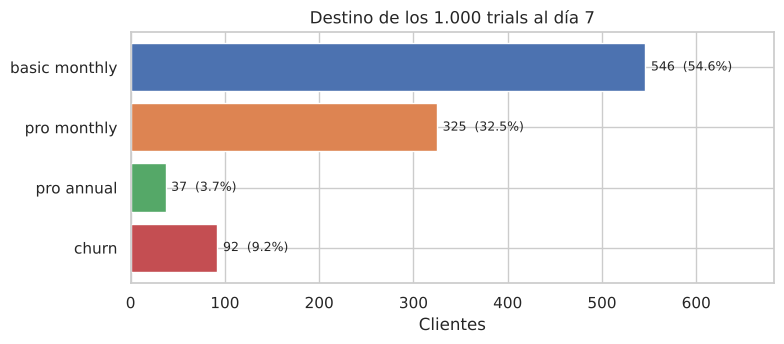

In [4]:
trial_outcome = (customers.assign(destino=customers["first_paid_plan"].fillna("churn"))
                 .groupby("destino").size().reindex(["basic monthly", "pro monthly", "pro annual", "churn"]))
trial_outcome_df = trial_outcome.rename("clientes").to_frame()
trial_outcome_df["%"] = (trial_outcome_df["clientes"] / n).map(pct)
display(trial_outcome_df)
assert trial_outcome.sum() == n

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [PLAN_COLORS[p] for p in trial_outcome.index]
bars = ax.barh(trial_outcome.index[::-1], trial_outcome.values[::-1], color=colors[::-1])
for b, v in zip(bars, trial_outcome.values[::-1]):
    ax.text(v + 6, b.get_y() + b.get_height() / 2, f"{v}  ({v / n:.1%})", va="center", fontsize=9)
ax.set_xlim(0, trial_outcome.max() * 1.25)
ax.set_title("Destino de los 1.000 trials al día 7")
ax.set_xlabel("Clientes"); ax.set_ylabel("")
fig.tight_layout(); save(fig, "02_funnel_trial_outcomes.png")

### Qué pasa después de pagar (ventana completa)
Para cada cliente que empezó en un plan **mensual** miro su destino. Sólo incluyo clientes con **al menos 184 días de observación desde su primer pago**:
como ningún evento ocurre pasado ese plazo (A2), el destino de esos clientes ya es definitivo y los porcentajes son comparables.
Las categorías son excluyentes. Se separa a quienes hicieron upgrade y **luego cancelaron**: sumados a quienes cancelaron sin upgrade dan la cancelación total, que es la cifra comparable entre planes.

outcome,"Upgrade, sigue activo",Upgrade y luego cancela,Sin cambios,Canceló sin upgrade,total
first_paid_plan,,,,,
basic monthly,237,41,95,68,441
pro monthly,62,1,144,65,272


Elegibles por plan inicial: {'basic monthly': 441, 'pro monthly': 272} | excluidos por ventana incompleta: 158


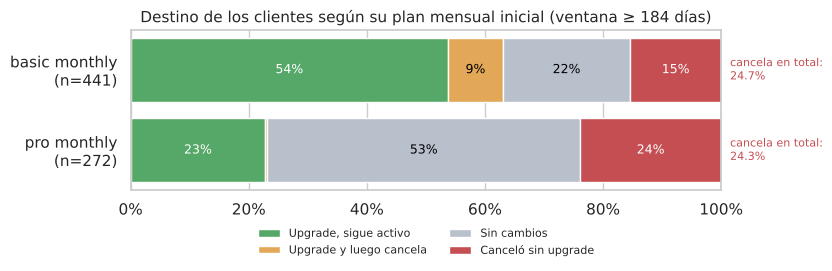

Cancelación total (con o sin upgrade previo):

 {'basic monthly': '24.7%', 'pro monthly': '24.3%'}


In [5]:
paid = customers[customers["converted_to_paid"]].copy()
paid["days_observed_paid"] = (OBSERVATION_END - paid["first_paid_date"]).dt.days
paid["complete_window"] = paid["days_observed_paid"] >= MONTHLY_CAP
paid["outcome"] = np.select(
    [(paid["n_upgrades"] > 0) & paid["is_churned"], paid["n_upgrades"] > 0, paid["is_churned"]],
    ["Upgrade y luego cancela", "Upgrade, sigue activo", "Canceló sin upgrade"], default="Sin cambios")

mon = paid[paid["first_paid_plan"].isin(MONTHLY) & paid["complete_window"]]
order_out = ["Upgrade, sigue activo", "Upgrade y luego cancela", "Sin cambios", "Canceló sin upgrade"]
UP_COLS = ["Upgrade, sigue activo", "Upgrade y luego cancela"]
outcome_ct = pd.crosstab(mon["first_paid_plan"], mon["outcome"]).reindex(columns=order_out).reindex(MONTHLY)
outcome_pct = outcome_ct.div(outcome_ct.sum(axis=1), axis=0)
# Cancelación TOTAL (con o sin upgrade previo): es la cifra comparable con la sección 8
churn_any = outcome_ct[["Upgrade y luego cancela", "Canceló sin upgrade"]].sum(axis=1) / outcome_ct.sum(axis=1)

display(outcome_ct.assign(total=outcome_ct.sum(axis=1)))
print("Elegibles por plan inicial:", outcome_ct.sum(axis=1).to_dict(),
      "| excluidos por ventana incompleta:", int((paid["first_paid_plan"].isin(MONTHLY) & ~paid["complete_window"]).sum()))

fig, ax = plt.subplots(figsize=(8.5, 3))
left = np.zeros(len(outcome_pct))
out_colors = {"Upgrade, sigue activo": "#55A868", "Upgrade y luego cancela": "#E3A857", "Sin cambios": "#B8C0CC", "Canceló sin upgrade": "#C44E52"}
for col in order_out:
    vals = outcome_pct[col].values
    ax.barh([f"{p}\n(n={outcome_ct.loc[p].sum()})" for p in outcome_pct.index], vals, left=left, color=out_colors[col], label=col)
    for i, (l, v) in enumerate(zip(left, vals)):
        if v < 0.03:
            continue                                   # evita etiquetas ilegibles en segmentos mínimos
        ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white" if col in ("Upgrade, sigue activo", "Canceló sin upgrade") else "black", fontsize=9)
    left += vals
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Destino de los clientes según su plan mensual inicial (ventana ≥ 184 días)", fontsize=11)
for i, p in enumerate(outcome_pct.index):
    ax.text(1.015, i, f"cancela en total:\n{churn_any[p]:.1%}", va="center", fontsize=8, color="#C44E52", clip_on=False)
ax.invert_yaxis()
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "02_outcome_by_starting_plan.png")

print("Cancelación total (con o sin upgrade previo):", {p: pct(v) for p, v in churn_any.items()})

> **Cómo leerlo:** "upgrade" significa cosas distintas en cada plan (desde *basic* se puede ir a *pro monthly* o *pro annual*; desde *pro monthly* sólo al anual),
> por eso **no comparo estadísticamente** estos porcentajes entre planes. Sirven para entender el destino de cada grupo.
> Los 37 clientes que arrancan directo en *pro annual* se analizan aparte: no pueden cancelar antes de 365 días, por diseño.

## 4. Conversión por cohorte
Cohorte = mes de inicio del trial. La conversión se decide al día 7, así que **no está afectada por la censura** y las cohortes son comparables.
Barras de error: intervalo de confianza de Wilson del 95 %.

,cohort_month,trials,convertidos,tasa,ic_inf,ic_sup
0,2020-01,88,77,87.5%,79.0%,92.9%
1,2020-02,68,63,92.6%,83.9%,96.8%
2,2020-03,94,87,92.6%,85.4%,96.3%
3,2020-04,81,72,88.9%,80.2%,94.0%
4,2020-05,88,80,90.9%,83.1%,95.3%
5,2020-06,79,74,93.7%,86.0%,97.3%
6,2020-07,89,78,87.6%,79.2%,93.0%
7,2020-08,88,84,95.5%,88.9%,98.2%
8,2020-09,87,80,92.0%,84.3%,96.0%
9,2020-10,79,69,87.3%,78.2%,93.0%


Test chi-cuadrado (conversión vs. cohorte): p = 0.732 → NO hay evidencia de diferencias entre cohortes


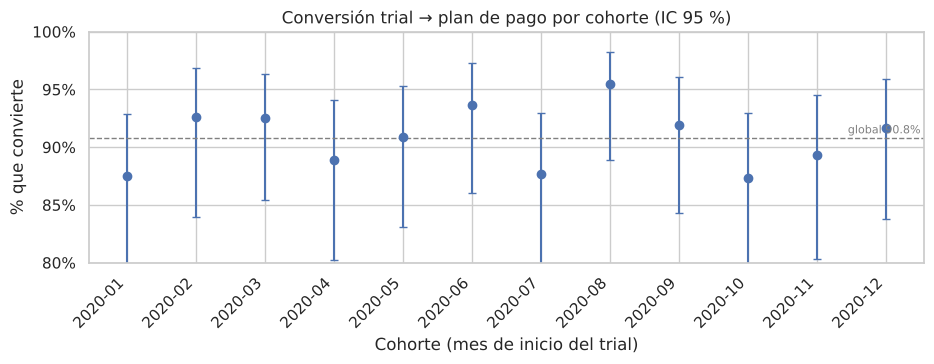

In [6]:
coh = (customers.groupby("cohort_month")
       .agg(trials=("customer_id", "size"), convertidos=("converted_to_paid", "sum")).reset_index())
coh["tasa"] = coh["convertidos"] / coh["trials"]
ci = [stats.binomtest(int(k), int(t)).proportion_ci(confidence_level=0.95, method="wilson") for k, t in zip(coh["convertidos"], coh["trials"])]
coh["ic_inf"], coh["ic_sup"] = [c.low for c in ci], [c.high for c in ci]

overall = conv / n
chi2, p_conv_cohort, _, _ = stats.chi2_contingency(pd.crosstab(customers["cohort_month"], customers["converted_to_paid"]))

display(coh.assign(tasa=coh["tasa"].map(pct), ic_inf=coh["ic_inf"].map(pct), ic_sup=coh["ic_sup"].map(pct)))
print(f"Test chi-cuadrado (conversión vs. cohorte): p = {p_conv_cohort:.3f} → "
      f"{'hay diferencias significativas' if p_conv_cohort < ALPHA else 'NO hay evidencia de diferencias entre cohortes'}")

fig, ax = plt.subplots(figsize=(9.5, 3.8))
x = np.arange(len(coh))
ax.errorbar(x, coh["tasa"], yerr=[coh["tasa"] - coh["ic_inf"], coh["ic_sup"] - coh["tasa"]],
            fmt="o", color="#4C72B0", capsize=3)
ax.axhline(overall, color="grey", ls="--", lw=1); ax.text(len(coh) - 0.5, overall + 0.004, f"global {overall:.1%}", ha="right", fontsize=8, color="grey")
ax.set_xticks(x); ax.set_xticklabels(coh["cohort_month"], rotation=45, ha="right")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylim(0.8, 1.0)
ax.set_title("Conversión trial → plan de pago por cohorte (IC 95 %)")
ax.set_xlabel("Cohorte (mes de inicio del trial)"); ax.set_ylabel("% que convierte")
fig.tight_layout(); save(fig, "02_conversion_by_cohort.png")

Todos los intervalos se solapan con la media global. Con 68–94 clientes por cohorte, **las diferencias aparentes entre meses son compatibles con el azar**.
Esto evita un error típico de portfolio: contar como "estacionalidad" lo que es ruido muestral.

## 5. Mezcla de planes
¿Qué plan eligen primero los clientes que convierten, y cómo cambia la base hasta el corte?

Test chi-cuadrado (plan inicial vs. cohorte): p = 0.296 → NO hay evidencia de que la mezcla cambie entre cohortes


,plan inicial (convertidos),% inicial,plan vigente (activos al corte),% vigente
basic monthly,546,60.1%,125,18.0%
pro monthly,325,35.8%,316,45.6%
pro annual,37,4.1%,252,36.4%


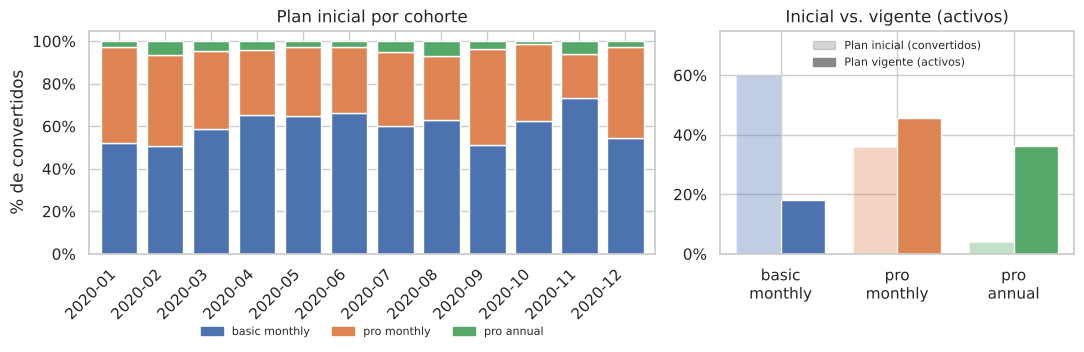

In [7]:
first_plan_ct = pd.crosstab(paid["cohort_month"], paid["first_paid_plan"]).reindex(columns=["basic monthly", "pro monthly", "pro annual"])
chi2_m, p_mix_cohort, _, _ = stats.chi2_contingency(first_plan_ct)
print(f"Test chi-cuadrado (plan inicial vs. cohorte): p = {p_mix_cohort:.3f} → "
      f"{'la mezcla cambia según la cohorte' if p_mix_cohort < ALPHA else 'NO hay evidencia de que la mezcla cambie entre cohortes'}")

start_mix = paid["first_paid_plan"].value_counts().reindex(["basic monthly", "pro monthly", "pro annual"])
act = customers[~customers["is_churned"]]
current_mix = act["current_plan"].value_counts().reindex(["basic monthly", "pro monthly", "pro annual"])
assert current_mix.sum() == active and start_mix.sum() == conv

mix_df = pd.DataFrame({"plan inicial (convertidos)": start_mix, "% inicial": (start_mix / start_mix.sum()).map(pct),
                       "plan vigente (activos al corte)": current_mix, "% vigente": (current_mix / current_mix.sum()).map(pct)})
display(mix_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.6, 1]})
first_plan_pct = first_plan_ct.div(first_plan_ct.sum(axis=1), axis=0)
first_plan_pct.plot(kind="bar", stacked=True, ax=axes[0], color=[PLAN_COLORS[c] for c in first_plan_pct.columns], width=.8, legend=False)
axes[0].set_title("Plan inicial por cohorte"); axes[0].set_xlabel(""); axes[0].set_ylabel("% de convertidos")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); plt.setp(axes[0].get_xticklabels(), rotation=45, ha="right")

w = 0.38; xs = np.arange(3)
cols_p = [PLAN_COLORS[p] for p in current_mix.index]
axes[1].bar(xs - w / 2, start_mix.values / start_mix.sum(), w, color=cols_p, alpha=.35)
axes[1].bar(xs + w / 2, current_mix.values / current_mix.sum(), w, color=cols_p)
axes[1].set_xticks(xs); axes[1].set_xticklabels(["basic\nmonthly", "pro\nmonthly", "pro\nannual"])
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); axes[1].set_title("Inicial vs. vigente (activos)")
axes[1].legend([plt.Rectangle((0, 0), 1, 1, color="#888", alpha=.35), plt.Rectangle((0, 0), 1, 1, color="#888")],
               ["Plan inicial (convertidos)", "Plan vigente (activos)"], frameon=False, fontsize=8, loc="upper center")
axes[1].set_ylim(0, 0.75)
h = [plt.Rectangle((0, 0), 1, 1, color=PLAN_COLORS[p]) for p in first_plan_pct.columns]
axes[0].legend(h, first_plan_pct.columns, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.28), frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "02_plan_mix.png")

La mezcla de planes **no varía entre cohortes** (el test no encuentra evidencia), pero **sí cambia mucho entre el plan de entrada y el plan vigente**:
el plan anual pasa de ser una minoría al elegir plan a representar una parte relevante de la base activa. El movimiento ocurre *después* de la conversión, por upgrades.

## 6. Recorridos de clientes
Secuencia completa de planes de cada cliente (`plan_path`).

,clientes,% de clientes,desenlace
plan_path,,,
trial > pro monthly,178,17.8%,activo al corte
trial > basic monthly > pro monthly,138,13.8%,activo al corte
trial > basic monthly,125,12.5%,activo al corte
trial > basic monthly > pro annual,107,10.7%,activo al corte
trial > basic monthly > churn,97,9.7%,churn
trial > churn,92,9.2%,churn
trial > pro monthly > pro annual,75,7.5%,activo al corte
trial > pro monthly > churn,71,7.1%,churn
trial > basic monthly > pro monthly > churn,41,4.1%,churn


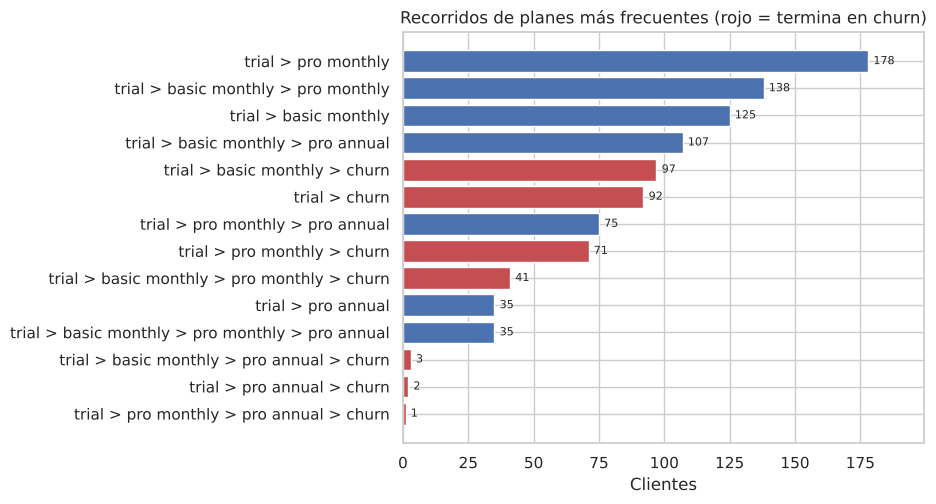

In [8]:
paths = customers["plan_path"].value_counts().rename("clientes").to_frame()
paths["% de clientes"] = (paths["clientes"] / n).map(pct)
paths["desenlace"] = [("churn" if p.endswith("churn") else "activo al corte") for p in paths.index]
display(paths)
assert paths["clientes"].sum() == n

fig, ax = plt.subplots(figsize=(9.5, 5.2))
colors = [PLAN_COLORS["churn"] if d == "churn" else "#4C72B0" for d in paths["desenlace"]]
ax.barh(paths.index[::-1], paths["clientes"].values[::-1], color=colors[::-1])
for i, v in enumerate(paths["clientes"].values[::-1]):
    ax.text(v + 2, i, str(v), va="center", fontsize=8)
ax.set_title("Recorridos de planes más frecuentes (rojo = termina en churn)")
ax.set_xlabel("Clientes"); ax.set_xlim(0, paths["clientes"].max() * 1.12)
fig.tight_layout(); save(fig, "02_top_paths.png")

Se observan 14 recorridos distintos y los 6 más frecuentes agrupan cerca del 74 % de los clientes. Se observan dos familias:
quienes **se quedan en el plan inicial** y quienes **escalan** (básico → pro mensual → anual); la cancelación aparece en cualquier punto.

## 7. Tiempos hasta upgrade o cancelación
Días entre el inicio de un plan y el evento siguiente. Se incluyen sólo clientes que **efectivamente tuvieron el evento**, así que describe *cuándo ocurre cuando ocurre*,
no la probabilidad de que ocurra.

eventos  mediana  p25  p75  máximo
tipo        desde                                            
Cancelación basic monthly       97       84   39  127     177
            pro annual           6      365  365  365     365
            pro monthly        112       90   42  129     179
            trial               92        7    7    7       7
Upgrade     basic monthly      324       92   48  130     179
            pro monthly        111       92   61  152     184

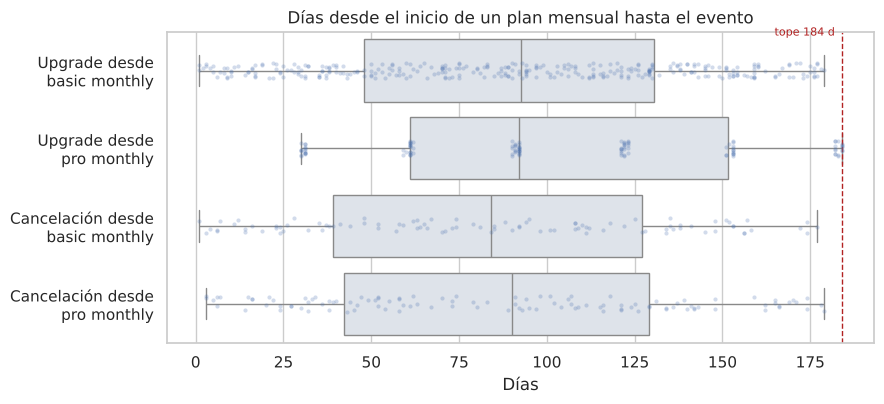

In [9]:
moves = events[events["is_upgrade"] | events["is_churn_event"]].copy()
moves["tipo"] = np.where(moves["is_upgrade"], "Upgrade", "Cancelación")
moves["desde"] = moves["prev_plan_name"]

timing = (moves.groupby(["tipo", "desde"])["gap_days"]
          .agg(eventos="size", mediana="median", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75), máximo="max")
          .round(0).astype(int))
display(timing)

# Gráfico: sólo planes mensuales (trial y anual tienen duración fija: 7 y 365 días)
plot_df = moves[moves["desde"].isin(MONTHLY)].copy()
plot_df["grupo"] = plot_df["tipo"] + " desde\n" + plot_df["desde"]
order_g = [f"{t} desde\n{p}" for t in ["Upgrade", "Cancelación"] for p in MONTHLY]

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.boxplot(data=plot_df, y="grupo", x="gap_days", order=order_g, color="#DCE3EC", fliersize=0, ax=ax)
sns.stripplot(data=plot_df, y="grupo", x="gap_days", order=order_g, color="#4C72B0", alpha=.25, size=3, ax=ax)
ax.axvline(MONTHLY_CAP, color="firebrick", ls="--", lw=1); ax.text(MONTHLY_CAP - 2, -0.45, f"tope {MONTHLY_CAP} d", color="firebrick", ha="right", fontsize=8)
ax.set_title("Días desde el inicio de un plan mensual hasta el evento")
ax.set_xlabel("Días"); ax.set_ylabel("")
fig.tight_layout(); save(fig, "02_time_to_event.png")

# Dos casos con duración fija, comprobados contra los datos
assert (moves[(moves["tipo"] == "Cancelación") & (moves["desde"] == "trial")]["gap_days"] == 7).all()
assert (moves[(moves["tipo"] == "Cancelación") & (moves["desde"] == "pro annual")]["gap_days"] == 365).all()

- **Trial:** todas las cancelaciones ocurren exactamente al día 7; las decisiones del trial son "todo o nada".
- **Planes mensuales:** upgrades y cancelaciones se reparten de forma amplia a lo largo de los primeros ~6 meses, con una mediana cercana a los 3 meses.
  No hay un momento único de "peligro": **el riesgo está repartido en toda la ventana**.
- **Plan anual:** la cancelación sólo se registra a los 365 días.

## 8. Churn: ¿cancela más quien está en el plan básico que en el pro mensual?

Comparar porcentajes crudos sería injusto: los clientes llevan distinto tiempo en cada plan. Uso una **tasa por exposición**:
cancelaciones por cada día-cliente en el plan, limitando la exposición a los primeros 184 días de cada tramo (después de ese plazo no puede haber eventos, ver A2, y diluiría ambas tasas).
Test: prueba exacta binomial condicional sobre las cancelaciones, ponderada por la exposición de cada plan (equivale a comparar dos tasas de Poisson).

In [10]:
spells = events[events["plan_name"].isin(MONTHLY)].copy()
spells["exposure_days"] = spells["days_in_plan"].astype(float).clip(upper=MONTHLY_CAP)
spells["churn_next"] = spells["next_plan_name"].eq("churn")
spells["upgrade_next"] = spells["next_plan_name"].isin(["pro monthly", "pro annual"])

rates = (spells.groupby("plan_name")
         .agg(tramos=("customer_id", "size"), exposición_días=("exposure_days", "sum"),
              cancelaciones=("churn_next", "sum"), upgrades=("upgrade_next", "sum")).reindex(MONTHLY))
rates["cancel. cada 30 días-cliente"] = rates["cancelaciones"] / rates["exposición_días"] * 30
rates["upgrades cada 30 días-cliente"] = rates["upgrades"] / rates["exposición_días"] * 30
display(rates.round(4))

# Comparación: básico vs pro mensual
kb, kp = int(rates.loc["basic monthly", "cancelaciones"]), int(rates.loc["pro monthly", "cancelaciones"])
eb, ep = rates.loc["basic monthly", "exposición_días"], rates.loc["pro monthly", "exposición_días"]
test = stats.binomtest(kb, kb + kp, p=eb / (eb + ep))
p_churn_plan = test.pvalue
share_ci = test.proportion_ci(method="exact")
to_rr = lambda s: (s / (1 - s)) * (ep / eb)           # participación de cancelaciones → razón de tasas
rate_ratio, rr_low, rr_high = to_rr(kb / (kb + kp)), to_rr(share_ci.low), to_rr(share_ci.high)

print(f"Razón de tasas (básico / pro mensual) = {rate_ratio:.2f}  [IC 95 %: {rr_low:.2f} – {rr_high:.2f}]  |  p = {p_churn_plan:.3f}")
print("→", "diferencia estadísticamente significativa" if p_churn_plan < ALPHA else "NO hay evidencia de diferencia entre planes")

,tramos,exposición_días,cancelaciones,upgrades,cancel. cada 30 días-cliente,upgrades cada 30 días-cliente
plan_name,,,,,,
basic monthly,546,59467.0,97,324,0.0489,0.1635
pro monthly,539,71890.0,112,111,0.0467,0.0463


Razón de tasas (básico / pro mensual) = 1.05  [IC 95 %: 0.79 – 1.39]  |  p = 0.781
→ NO hay evidencia de diferencia entre planes


In [11]:
# Chequeo de robustez: misma pregunta con otro método (ventana completa, 'canceló' = canceló alguna vez)
b = paid[(paid["first_paid_plan"] == "basic monthly") & paid["complete_window"]]
p_ = paid[(paid["first_paid_plan"] == "pro monthly") & paid["complete_window"]]
tab = np.array([[b["is_churned"].sum(), (~b["is_churned"]).sum()], [p_["is_churned"].sum(), (~p_["is_churned"]).sum()]])
p_robust = stats.fisher_exact(tab)[1]
print(f"Ventana completa → cancelaron: básico {tab[0,0]}/{tab[0].sum()} ({pct(tab[0,0]/tab[0].sum())}) vs pro mensual {tab[1,0]}/{tab[1].sum()} ({pct(tab[1,0]/tab[1].sum())}) | Fisher p = {p_robust:.3f}")

Ventana completa → cancelaron: básico 109/441 (24.7%) vs pro mensual 66/272 (24.3%) | Fisher p = 0.929


Dos métodos independientes llegan a la misma conclusión: **no hay evidencia de que el plan de entrada (básico o pro mensual) cambie el riesgo de cancelar**.
Precio más alto no se traduce en más churn en este dataset (y viceversa).

## 9. Upgrades: cuándo ocurren
Curva de **incidencia acumulada** del *primer evento* tras el primer pago: qué porcentaje de los clientes que empezaron en un plan mensual
ya hizo upgrade (verde) o canceló (rojo) a los *t* días. Sólo clientes con ventana completa (≥ 184 días).

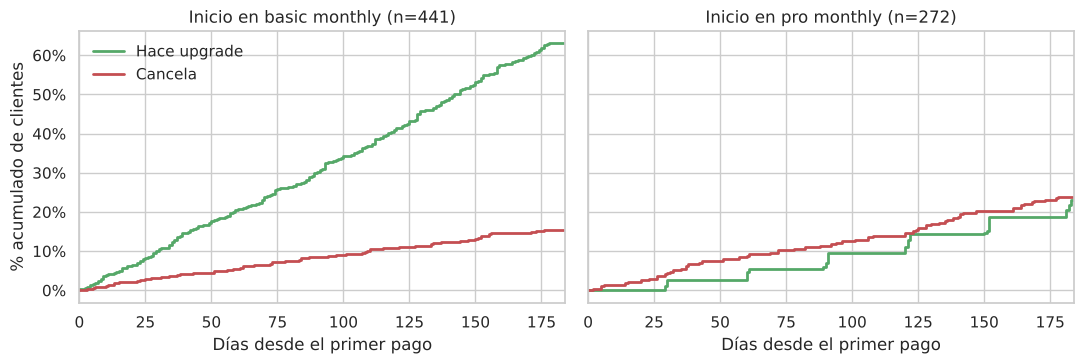

,plan inicial,día,upgrade acumulado,cancelación acumulada
0,basic monthly,30,10.0%,3.2%
1,basic monthly,90,29.9%,8.4%
2,basic monthly,184,63.0%,15.4%
3,pro monthly,30,1.1%,4.0%
4,pro monthly,90,5.9%,11.4%
5,pro monthly,184,23.2%,23.9%


In [12]:
conv_rows = events[events["is_conversion"] & events["plan_name"].isin(MONTHLY)].copy()
conv_rows["t_next"] = (conv_rows["next_start_date"] - conv_rows["start_date"]).dt.days
conv_rows["tipo"] = np.select([conv_rows["next_plan_name"].eq("churn"), conv_rows["next_plan_name"].notna()],
                              ["cancela", "upgrade"], default="ninguno")
conv_rows = conv_rows[(OBSERVATION_END - conv_rows["start_date"]).dt.days >= MONTHLY_CAP]
assert len(conv_rows) == int(outcome_ct.sum().sum())      # mismos clientes que en la sección 3

days = np.arange(0, MONTHLY_CAP + 1)
def cum_incidence(df, kind):
    t = df.loc[df["tipo"] == kind, "t_next"].values
    return np.array([(t <= d).sum() for d in days]) / len(df)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
cum_rows = []
for ax, plan in zip(axes, MONTHLY):
    d = conv_rows[conv_rows["plan_name"] == plan]
    up, ca = cum_incidence(d, "upgrade"), cum_incidence(d, "cancela")
    ax.step(days, up, color="#55A868", lw=2, label="Hace upgrade"); ax.step(days, ca, color="#C44E52", lw=2, label="Cancela")
    ax.set_title(f"Inicio en {plan} (n={len(d)})"); ax.set_xlabel("Días desde el primer pago")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xlim(0, MONTHLY_CAP)
    for t in (30, 90, MONTHLY_CAP):
        cum_rows.append({"plan inicial": plan, "día": t, "upgrade acumulado": up[t], "cancelación acumulada": ca[t]})
axes[0].set_ylabel("% acumulado de clientes"); axes[0].legend(frameon=False)
fig.tight_layout(); save(fig, "02_cumulative_incidence.png")

cum_tab = pd.DataFrame(cum_rows)
display(cum_tab.assign(**{"upgrade acumulado": cum_tab["upgrade acumulado"].map(pct), "cancelación acumulada": cum_tab["cancelación acumulada"].map(pct)}))

- **Desde *basic*:** los upgrades crecen de forma sostenida durante toda la ventana, sin un pico temprano; las cancelaciones crecen más despacio.
- **Desde *pro monthly*:** los upgrades (hacia el anual) no son graduales sino **en escalones**, cerca de los 30, 60, 90, 120 y 150 días. La celda siguiente mide si coinciden con la fecha de renovación mensual.
- Las cancelaciones crecen de forma pareja en ambos planes.

In [13]:
# ¿Los eventos ocurren el mismo día del mes en que empezó el plan (fecha de renovación mensual)?
anniv = moves[moves["desde"].isin(MONTHLY)].copy()
anniv["mismo_día_del_mes"] = anniv["start_date"].dt.day == anniv["prev_start_date"].dt.day
anniv_tab = anniv.groupby(["tipo", "desde"])["mismo_día_del_mes"].agg(eventos="size", pct_en_renovación="mean")
display(anniv_tab.assign(pct_en_renovación=anniv_tab["pct_en_renovación"].map(pct)))

# Con un evento al azar esperaríamos ~1/30 ≈ 3 %: sólo el upgrade pro mensual → anual se aparta de eso
renew_up_pro = anniv_tab.loc[("Upgrade", "pro monthly"), "pct_en_renovación"]
assert renew_up_pro > 0.9
assert anniv_tab.drop(index=("Upgrade", "pro monthly"))["pct_en_renovación"].max() < 0.1
print(f"✔ {pct(renew_up_pro)} de los upgrades de pro mensual a anual ocurren en la fecha de renovación mensual; el resto de los eventos, no.")

eventos pct_en_renovación
tipo        desde                                   
Cancelación basic monthly       97              3.1%
            pro monthly        112              3.6%
Upgrade     basic monthly      324              2.5%
            pro monthly        111             97.3%

✔ 97.3% de los upgrades de pro mensual a anual ocurren en la fecha de renovación mensual; el resto de los eventos, no.


**Lectura:** el pasaje de *pro monthly* a *pro annual* ocurre prácticamente siempre **en la fecha de renovación mensual**, mientras que los upgrades desde *basic* y
todas las cancelaciones ocurren en días arbitrarios. En un negocio real esto sugeriría que la renovación es el momento natural de decisión para pasar al anual.
Al ser datos sintéticos, el patrón puede ser una regla de generación; aun así es un hallazgo medible y se incorpora a las recomendaciones como hipótesis a validar.

## 10. Valor estimado de la base activa
**Estimación con precios de lista**: el plan anual se expresa como equivalente mensual (precio ÷ 12). No son pagos reales, y el resultado depende
del supuesto A1 (anuales vencidos sin evento = renovados), por lo que se muestra también una sensibilidad.

{'basic monthly': 9.9, 'pro monthly': 19.9, 'pro annual': 16.58}


,clientes,valor_mensual_eq,% clientes,% valor
current_plan,,,,
basic monthly,125,1238.0,18.0%,10.6%
pro monthly,316,6288.0,45.6%,53.7%
pro annual,252,4179.0,36.4%,35.7%


Sensibilidad (sin los 19 anuales dudosos): anual = 34.6% de los clientes y 33.9% del valor


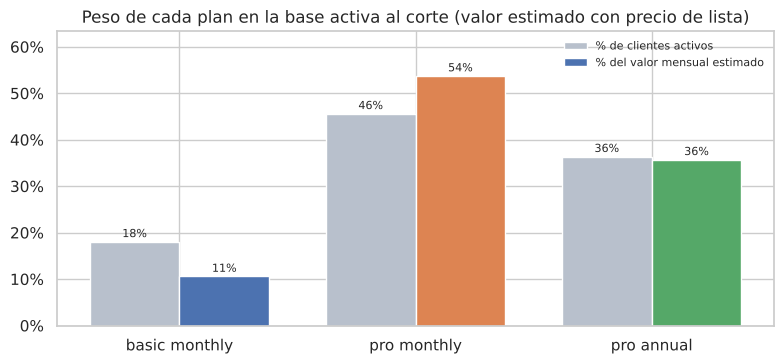

In [14]:
price = events.drop_duplicates("plan_name").set_index("plan_name")["price"]
monthly_eq = {"basic monthly": float(price["basic monthly"]), "pro monthly": float(price["pro monthly"]), "pro annual": float(price["pro annual"]) / 12}
print({k: round(v, 2) for k, v in monthly_eq.items()})

def value_table(df):
    t = df["current_plan"].value_counts().reindex(["basic monthly", "pro monthly", "pro annual"]).rename("clientes").to_frame()
    t["valor_mensual_eq"] = [t.loc[p, "clientes"] * monthly_eq[p] for p in t.index]
    t["% clientes"] = t["clientes"] / t["clientes"].sum()
    t["% valor"] = t["valor_mensual_eq"] / t["valor_mensual_eq"].sum()
    return t

value_all = value_table(act)
value_excl = value_table(act[~act["annual_term_expired_no_event"]])      # sensibilidad: sin los 19 anuales dudosos
display(value_all.assign(**{"% clientes": value_all["% clientes"].map(pct), "% valor": value_all["% valor"].map(pct), "valor_mensual_eq": value_all["valor_mensual_eq"].round(0)}))
print(f"Sensibilidad (sin los {int(act['annual_term_expired_no_event'].sum())} anuales dudosos): anual = "
      f"{pct(value_excl.loc['pro annual', '% clientes'])} de los clientes y {pct(value_excl.loc['pro annual', '% valor'])} del valor")

fig, ax = plt.subplots(figsize=(8, 3.8))
xs = np.arange(3); w = 0.38
ax.bar(xs - w / 2, value_all["% clientes"], w, label="% de clientes activos", color="#B8C0CC")
ax.bar(xs + w / 2, value_all["% valor"], w, label="% del valor mensual estimado", color=[PLAN_COLORS[p] for p in value_all.index])
for i, (a, b) in enumerate(zip(value_all["% clientes"], value_all["% valor"])):
    ax.text(i - w / 2, a + .01, f"{a:.0%}", ha="center", fontsize=8); ax.text(i + w / 2, b + .01, f"{b:.0%}", ha="center", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels(value_all.index); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Peso de cada plan en la base activa al corte (valor estimado con precio de lista)")
ax.legend(frameon=False, fontsize=8); ax.set_ylim(0, value_all[["% clientes", "% valor"]].values.max() * 1.18)
fig.tight_layout(); save(fig, "02_active_base_value.png")

## 11. Hallazgos
Formato **Finding / Evidence / Impact / Recommendation**. Todas las cifras se calculan en este notebook (no están escritas a mano) y las afirmaciones
sobre diferencias están protegidas por `assert`: si los datos cambiaran y la afirmación dejara de ser cierta, el notebook se detiene.
Las recomendaciones son **preliminares**; se consolidarán en el notebook 05 junto con cohortes y segmentación.

In [15]:
# ── Cifras base para los hallazgos ──
conv_rate = conv / n
paid_share_of_churn = churn_paid / churn_total
up_any = outcome_pct[UP_COLS].sum(axis=1)                       # % que hizo al menos un upgrade (con o sin cancelación posterior)
up_b, up_p = up_any["basic monthly"], up_any["pro monthly"]
n_b, n_p = int(outcome_ct.loc["basic monthly"].sum()), int(outcome_ct.loc["pro monthly"].sum())
med_up_b = timing.loc[("Upgrade", "basic monthly"), "mediana"]; med_up_p = timing.loc[("Upgrade", "pro monthly"), "mediana"]
med_ch_b = timing.loc[("Cancelación", "basic monthly"), "mediana"]; med_ch_p = timing.loc[("Cancelación", "pro monthly"), "mediana"]
q = lambda plan, kind, t: cum_tab[(cum_tab["plan inicial"] == plan) & (cum_tab["día"] == t)][f"{kind} acumulad{'o' if kind == 'upgrade' else 'a'}"].item()
n_upgrade_events = int(moves["is_upgrade"].sum())
n_churn_from_monthly = int(((moves["tipo"] == "Cancelación") & moves["desde"].isin(MONTHLY)).sum())
annual_direct = int((paid["first_paid_plan"] == "pro annual").sum())
annual_active = int(current_mix["pro annual"])
annual_via_upgrade = annual_active - int(((act["current_plan"] == "pro annual") & (act["first_paid_plan"] == "pro annual")).sum())

# ── Afirmaciones que sostienen la narrativa (si fallan, el texto ya no es válido) ──
assert p_conv_cohort >= ALPHA and p_mix_cohort >= ALPHA          # sin diferencias entre cohortes
assert p_churn_plan >= ALPHA and p_robust >= ALPHA               # sin diferencias de churn entre planes mensuales
assert paid_share_of_churn > 0.5                                 # la mayor parte del churn ocurre tras pagar
assert n_upgrade_events > n_churn_from_monthly                   # tras convertir hay más upgrades que cancelaciones
assert annual_active > annual_direct * 3                         # el anual crece sobre todo por upgrades
assert current_mix["pro annual"] / current_mix.sum() > start_mix["pro annual"] / start_mix.sum()
print("✔ Todas las afirmaciones de los hallazgos están respaldadas por los datos.")

✔ Todas las afirmaciones de los hallazgos están respaldadas por los datos.


In [16]:
display(Markdown(f'''
### Hallazgo 1 · El trial convierte muy bien y la conversión es homogénea entre meses
- **Finding:** el embudo de entrada no es el problema: casi todos los trials pasan a pagar, sin diferencias entre cohortes.
- **Evidence:** {conv} de {n} trials convierten ({pct(conv_rate)}); sólo {churn_trial} ({pct(churn_trial / n)}) cancelan al día 7. La conversión por cohorte no difiere de forma significativa (chi-cuadrado, p = {p_conv_cohort:.2f}), ni tampoco la mezcla de planes elegidos (p = {p_mix_cohort:.2f}).
- **Impact:** optimizar el trial tendría poco margen (techo máximo: {churn_trial} clientes). No hay evidencia de estacionalidad en la captación.
- **Recommendation (preliminar):** no priorizar mejoras del trial; proteger la experiencia actual y concentrar el esfuerzo después de la conversión.

### Hallazgo 2 · La mayor parte del churn ocurre después de que el cliente ya pagó
- **Finding:** cancelar es principalmente un problema de retención, no de adquisición.
- **Evidence:** de {churn_total} cancelaciones, {churn_paid} ({pct(paid_share_of_churn)}) son de clientes que habían pagado. En planes mensuales, las cancelaciones ocurren con una mediana de {med_ch_b:.0f} días (básico) y {med_ch_p:.0f} días (pro mensual) desde el inicio del plan, repartidas a lo largo de toda la ventana de {MONTHLY_CAP} días.
- **Impact:** no existe un "momento crítico" único; el riesgo está distribuido durante los primeros ~6 meses de un plan mensual.
- **Recommendation (preliminar):** diseñar acciones de retención **sostenidas en los primeros 6 meses** (por ejemplo, contacto periódico o beneficios de permanencia) en lugar de una única intervención puntual.

### Hallazgo 3 · El plan mensual (básico o pro) no cambia el riesgo de cancelar
- **Finding:** no hay evidencia de que el nivel de precio del plan mensual influya en la cancelación.
- **Evidence:** razón de tasas de cancelación por día-cliente, básico / pro mensual = {rate_ratio:.2f} (IC 95 %: {rr_low:.2f}–{rr_high:.2f}; p = {p_churn_plan:.2f}). Un segundo método, por plan *inicial* y con ventana completa, coincide: cancelaron en algún momento {pct(tab[0,0]/tab[0].sum())} de los que empezaron en básico vs. {pct(tab[1,0]/tab[1].sum())} de los que empezaron en pro mensual (Fisher p = {p_robust:.2f}).
- **Impact:** segmentar las acciones de retención por plan mensual no está respaldado por estos datos; el pro mensual no es "más riesgoso" ni "más estable" que el básico.
- **Recommendation (preliminar):** aplicar las acciones de retención de forma uniforme entre planes mensuales hasta contar con variables que realmente diferencien el riesgo. *(No se afirma que sean iguales: un intervalo amplio indica que el dataset no permite descartar diferencias moderadas.)*

### Hallazgo 4 · Tras convertir, el principal movimiento de los clientes son los upgrades, y el pasaje al anual ocurre en la renovación mensual
- **Finding:** los clientes se mueven hacia planes de mayor nivel con más frecuencia de la que cancelan, y el paso de pro mensual a anual sigue un patrón de renovación.
- **Evidence:** entre planes mensuales hay {n_upgrade_events} upgrades frente a {n_churn_from_monthly} cancelaciones. Con ventana completa, {pct(up_b)} de los que arrancan en básico (n={n_b}) y {pct(up_p)} de los que arrancan en pro mensual (n={n_p}) hacen al menos un upgrade. La mediana del upgrade es de {med_up_b:.0f} días (básico) y {med_up_p:.0f} días (pro mensual); a los 90 días ya hizo upgrade el {pct(q('basic monthly', 'upgrade', 90))} (básico) y el {pct(q('pro monthly', 'upgrade', 90))} (pro mensual). El {pct(renew_up_pro)} de los upgrades de pro mensual a anual ocurre en la fecha de renovación mensual, frente a ~3 % en el resto de los eventos.
- **Impact:** pasar de básico a pro duplica el precio de lista mensual (de {monthly_eq['basic monthly']:.2f} a {monthly_eq['pro monthly']:.2f}), y los upgrades se reparten durante meses: hay una ventana de oportunidad larga, no un instante.
- **Recommendation (preliminar):** (a) sostener propuestas de upgrade **desde el primer mes y durante todo el semestre** para clientes del plan básico; (b) ubicar la oferta del plan anual **en el momento de renovación mensual** de los clientes pro mensual; (c) medir ambas con un grupo de control, porque estos datos muestran asociación, no efecto causal.

### Hallazgo 5 · El plan anual pesa mucho más en la base actual que al momento de elegir plan
- **Finding:** casi nadie entra por el plan anual, pero una porción importante de la base termina en él.
- **Evidence:** sólo {annual_direct} clientes ({pct(annual_direct / conv)} de los convertidos) eligen el anual de entrada, pero {annual_active} clientes activos lo tienen al corte ({pct(current_mix['pro annual'] / current_mix.sum())} de la base activa, {pct(value_all.loc['pro annual', '% valor'])} del valor mensual estimado); {annual_via_upgrade} llegaron por upgrade. Sensibilidad A1 (sin los 19 anuales vencidos sin evento): {pct(value_excl.loc['pro annual', '% clientes'])} de los clientes y {pct(value_excl.loc['pro annual', '% valor'])} del valor.
- **Impact:** el anual es el destino al que llegan los clientes que escalan y concentra una parte significativa del valor. Su retención real **no es medible aún**: la cancelación sólo se registra a los 365 días y existen anuales vencidos sin evento.
- **Recommendation (preliminar):** (a) probar incentivos de pasaje al anual para clientes mensuales; (b) **registrar explícitamente las renovaciones** en los datos, porque hoy no se puede distinguir renovación de churn no registrado.
'''))


### Hallazgo 1 · El trial convierte muy bien y la conversión es homogénea entre meses
- **Finding:** el embudo de entrada no es el problema: casi todos los trials pasan a pagar, sin diferencias entre cohortes.
- **Evidence:** 908 de 1000 trials convierten (90.8%); sólo 92 (9.2%) cancelan al día 7. La conversión por cohorte no difiere de forma significativa (chi-cuadrado, p = 0.73), ni tampoco la mezcla de planes elegidos (p = 0.30).
- **Impact:** optimizar el trial tendría poco margen (techo máximo: 92 clientes). No hay evidencia de estacionalidad en la captación.
- **Recommendation (preliminar):** no priorizar mejoras del trial; proteger la experiencia actual y concentrar el esfuerzo después de la conversión.

### Hallazgo 2 · La mayor parte del churn ocurre después de que el cliente ya pagó
- **Finding:** cancelar es principalmente un problema de retención, no de adquisición.
- **Evidence:** de 307 cancelaciones, 215 (70.0%) son de clientes que habían pagado. En planes mensuales, las cancelaciones ocurren con una mediana de 84 días (básico) y 90 días (pro mensual) desde el inicio del plan, repartidas a lo largo de toda la ventana de 184 días.
- **Impact:** no existe un "momento crítico" único; el riesgo está distribuido durante los primeros ~6 meses de un plan mensual.
- **Recommendation (preliminar):** diseñar acciones de retención **sostenidas en los primeros 6 meses** (por ejemplo, contacto periódico o beneficios de permanencia) en lugar de una única intervención puntual.

### Hallazgo 3 · El plan mensual (básico o pro) no cambia el riesgo de cancelar
- **Finding:** no hay evidencia de que el nivel de precio del plan mensual influya en la cancelación.
- **Evidence:** razón de tasas de cancelación por día-cliente, básico / pro mensual = 1.05 (IC 95 %: 0.79–1.39; p = 0.78). Un segundo método, por plan *inicial* y con ventana completa, coincide: cancelaron en algún momento 24.7% de los que empezaron en básico vs. 24.3% de los que empezaron en pro mensual (Fisher p = 0.93).
- **Impact:** segmentar las acciones de retención por plan mensual no está respaldado por estos datos; el pro mensual no es "más riesgoso" ni "más estable" que el básico.
- **Recommendation (preliminar):** aplicar las acciones de retención de forma uniforme entre planes mensuales hasta contar con variables que realmente diferencien el riesgo. *(No se afirma que sean iguales: un intervalo amplio indica que el dataset no permite descartar diferencias moderadas.)*

### Hallazgo 4 · Tras convertir, el principal movimiento de los clientes son los upgrades, y el pasaje al anual ocurre en la renovación mensual
- **Finding:** los clientes se mueven hacia planes de mayor nivel con más frecuencia de la que cancelan, y el paso de pro mensual a anual sigue un patrón de renovación.
- **Evidence:** entre planes mensuales hay 435 upgrades frente a 209 cancelaciones. Con ventana completa, 63.0% de los que arrancan en básico (n=441) y 23.2% de los que arrancan en pro mensual (n=272) hacen al menos un upgrade. La mediana del upgrade es de 92 días (básico) y 92 días (pro mensual); a los 90 días ya hizo upgrade el 29.9% (básico) y el 5.9% (pro mensual). El 97.3% de los upgrades de pro mensual a anual ocurre en la fecha de renovación mensual, frente a ~3 % en el resto de los eventos.
- **Impact:** pasar de básico a pro duplica el precio de lista mensual (de 9.90 a 19.90), y los upgrades se reparten durante meses: hay una ventana de oportunidad larga, no un instante.
- **Recommendation (preliminar):** (a) sostener propuestas de upgrade **desde el primer mes y durante todo el semestre** para clientes del plan básico; (b) ubicar la oferta del plan anual **en el momento de renovación mensual** de los clientes pro mensual; (c) medir ambas con un grupo de control, porque estos datos muestran asociación, no efecto causal.

### Hallazgo 5 · El plan anual pesa mucho más en la base actual que al momento de elegir plan
- **Finding:** casi nadie entra por el plan anual, pero una porción importante de la base termina en él.
- **Evidence:** sólo 37 clientes (4.1% de los convertidos) eligen el anual de entrada, pero 252 clientes activos lo tienen al corte (36.4% de la base activa, 35.7% del valor mensual estimado); 217 llegaron por upgrade. Sensibilidad A1 (sin los 19 anuales vencidos sin evento): 34.6% de los clientes y 33.9% del valor.
- **Impact:** el anual es el destino al que llegan los clientes que escalan y concentra una parte significativa del valor. Su retención real **no es medible aún**: la cancelación sólo se registra a los 365 días y existen anuales vencidos sin evento.
- **Recommendation (preliminar):** (a) probar incentivos de pasaje al anual para clientes mensuales; (b) **registrar explícitamente las renovaciones** en los datos, porque hoy no se puede distinguir renovación de churn no registrado.


## 12. Limitaciones y próximos pasos

**Qué NO permite concluir este análisis**
- **Retención de largo plazo:** por el tope de 184 días (A2), no se puede afirmar nada sobre lealtad a más de ~6 meses en planes mensuales.
- **Retención del plan anual:** sólo hay 25 anuales vencidos al corte y 19 de ellos sin evento (A1).
- **Causalidad:** los datos son observacionales; "los upgrades generan valor" describe asociación y flujo de clientes, no el efecto de una campaña.
- **Ingresos:** estimados con precio de lista; no hay descuentos, reembolsos ni pagos reales.
- **Generalización:** el dataset es sintético por origen; patrones como el tope temporal de 184 días y los upgrades alineados a la renovación son compatibles con reglas de generación y no deben extrapolarse a negocios reales.
- **Múltiples tests:** se realizaron varios contrastes con α = 0,05 sin corrección formal; las conclusiones de "sin diferencia" no dependen de ello, pero cualquier hallazgo "significativo" futuro debería leerse con esa cautela.

**Qué sigue**
**`03_cohorts_retention_churn.ipynb`** — tablas de retención por cohorte en **ventanas equivalentes**, curvas de supervivencia (Kaplan-Meier) por plan inicial y análisis de sensibilidad para el supuesto A1.